# 12. Settled, Then a Spike

> **Overview.** In a network that runs for a long time, search mostly works from settled statistics, and what matters
> is what it does when one output's error suddenly spikes. With 20 outputs instead of 100, the memory holds a few
> tries of every output, so its statistics can settle before anything changes. Do new LTUs then stay off decoys, and
> go to an output whose error spikes?

**Setup.** Notebook 11's learner: 32 LTUs, a search step every 10k steps. 20 outputs: the first 2 each read 4 of 8
target LTUs; the other 18 (decoys) are noise or noisy linear. Nothing changes for 200k steps; then every 100k steps
one output changes, alternating: one of the 2 learnable outputs reads 2 new target LTUs instead (its error spikes);
or one of them becomes a decoy, and a decoy reads 2 new target LTUs (a decoy becomes a target). Parents are drawn:
- uniformly (current method);
- in proportion to each output's error $L_o$ times its explained fraction $e_o$ (notebook 4a);
- half uniformly, half in proportion to $L_o$ times $q_o$, the mean outcome of the LTUs tried on that output, with
  one pseudo-trial at $e_o$ (notebook 11);
- **(proposed)** the same, with $e_o$ standing in only until the output has been tried.

Against an oracle (the output reading target LTUs, the newest needle after a change). 5 seeds; 600k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 20
N_IMPROVABLE = 2                     # the first outputs, each reading target LTUs at first; the rest are decoys
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STD = 0.1                      # observation noise on outputs that read target LTUs: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE on such an output
N_CHANGES = 4                        # changes, one output at a time, alternating: a learnable output changes; a
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000  # decoy becomes a target (and a learnable output a decoy)
N_NEW = 2                            # new target LTUs the changed output reads
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, EXPLAINED, AVERAGED, UNTIL_TRIED, ORACLE = range(5)   # how a new LTU's parent output is drawn
NOISE, NOISY_LINEAR = range(2)                                 # kinds of decoy

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, N_OUTPUTS, N_ALL_TARGETS): the outputs' weights on them, by version
    noise_std: jax.Array        # (N_CHANGES + 1, N_OUTPUTS): each output's noise, by version
    needle: jax.Array           # (N_CHANGES + 1,): the newest output reading new target LTUs (-1 before any change)
    linear: jax.Array           # (N_CHANGES + 1, N_OUTPUTS, N_INPUTS): the decoys' linear weights, by version


def make_target(key, kind):
    # Version 0: the first N_IMPROVABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise NOISE_STD. The others (decoys) are noise of
    # unit variance, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs (its own, drawn for
    # every output) with random +-1 weights scaled to unit variance. Each target LTU reads N_SOURCES inputs drawn at
    # random, with random +-1 weights. Change c makes version c + 1: if c is even, a learnable output, at random, reads
    # the next N_NEW target LTUs instead (its error spikes); if odd, one of them becomes a decoy, and a decoy, at
    # random, reads the next N_NEW (a decoy becomes a target).
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < N_IMPROVABLE
    reads = jnp.pad(pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    noise_std = jnp.where(first[:, 0], NOISE_STD, 1.0)
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (kind != NOISE))
    outs, noise_stds, needles, linears = [out], [noise_std], [jnp.array(-1)], [linear * ~first]
    for c in range(N_CHANGES):
        sign_key, old_key, new_key = jax.random.split(jax.random.fold_in(change_key, c), 3)
        improvable = (out != 0).any(1)
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        row = jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW)
        old = jax.random.categorical(old_key, jnp.log(improvable))
        if c % 2 == 0:
            needle = old
        else:
            needle = jax.random.categorical(new_key, jnp.log(~improvable))
            out, noise_std = out.at[old].set(0.0), noise_std.at[old].set(1.0)
        out, noise_std = out.at[needle].set(row), noise_std.at[needle].set(NOISE_STD)
        outs, noise_stds, needles = outs + [out], noise_stds + [noise_std], needles + [needle]
        linears = linears + [linear * ~(out != 0).any(1)[:, None]]
    return Target(w, jnp.stack(outs), jnp.stack(noise_stds), jnp.stack(needles), jnp.stack(linears))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

Notebook 11's learner, searching every 10k steps; its memory may let the explained fraction stand in only until an
output has been tried.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (N_OUTPUTS,): each output's summed squared error since the last search step
    target_sum: jax.Array       # (N_OUTPUTS,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    birth: jax.Array            # (N_LTUS,): its parent's mean squared error when search added it (NaN: the first LTUs)
    dead_sum: jax.Array         # (N_OUTPUTS,): replaced trials' outcomes, summed by parent, fading by the replaced share per search step
    dead_count: jax.Array       # (N_OUTPUTS,): their number, fading likewise


def init_net(key, target):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform weights;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES
    readers = target.out[0][:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)),
               *(jnp.zeros(N_OUTPUTS),) * 3, jnp.full(N_LTUS, jnp.nan), jnp.zeros(N_OUTPUTS), jnp.zeros(N_OUTPUTS))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits (one row for all LTUs, or a row each). It reads FAN_IN inputs and the bias,
    # the inputs drawn without replacement with probability proportional to the square of the parent's linear weight
    # on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and each output's squared error on this sample, before learning from it, which it also
    # adds to loss_sum; adds the targets and their squares to target_sum and target_sq_sum, and dL/dz * x_i to each
    # LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                      jax.lax.stop_gradient(prediction - y) ** 2)

    (_, (source, h, mean, squared)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared,
                        target_sum=net.target_sum + y, target_sq_sum=net.target_sq_sum + y ** 2), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's sum of squared outgoing weights: about the increase in the squared error, summed over the outputs, if
    # it were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def explained_fraction(net):
    # Each output's explained fraction over this search period, (V - L) / V, with L its mean squared error and V its
    # targets' variance (0 if negative).
    loss = net.loss_sum / PERIOD
    variance = net.target_sq_sum / PERIOD - (net.target_sum / PERIOD) ** 2
    return jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)


def outcomes(net):
    # Each LTU added by search (a trial): its squared weight to its parent, the error its removal would add there, over
    # its parent's mean squared error when it was added; 0 for the first LTUs.
    parent = jnp.argmax(jnp.abs(net.shadow), 0)
    trial = ~jnp.isnan(net.birth)
    own = net.w['output'][parent, N_INPUTS + jnp.arange(N_LTUS)] ** 2
    return trial, jnp.where(trial, own / jnp.maximum(jnp.nan_to_num(net.birth), 1e-30), 0.0)


def remembered(net, fraction, until_tried):
    # Each output's mean outcome over the trials it is or was the parent of, the replaced ones (fading) and the current
    # ones, plus a pseudo-trial at its explained fraction: of weight 1, or, if until_tried, of the weight its trials
    # lack below 1.
    trial, f = outcomes(net)
    parent = jnp.argmax(jnp.abs(net.shadow), 0)
    total = net.dead_sum + jnp.zeros(N_OUTPUTS).at[parent].add(f)
    count = net.dead_count + jnp.zeros(N_OUTPUTS).at[parent].add(trial * 1.0)
    prior = jnp.where(until_tried, jnp.maximum(1 - count, 0.0), 1.0)
    return (total + prior * fraction) / (count + prior)


def parent_logits(net, rule, needle, improvable):
    # Log-probabilities of each output being a new LTU's parent, in proportion to its mean squared error L since the
    # last search step times its explained fraction e (EXPLAINED) or its remembered outcomes (AVERAGED, UNTIL_TRIED);
    # uniform; or the oracle: the needle, or uniform among the outputs reading target LTUs. Uniform while all weights
    # are 0.
    def share(weight):
        weight = jnp.maximum(weight, 0.0)
        return jnp.where(weight.sum() > 0, weight / jnp.maximum(weight.sum(), 1e-30), 1 / N_OUTPUTS)

    loss, fraction = net.loss_sum / PERIOD, explained_fraction(net)
    oracle = jnp.where(needle >= 0, jnp.arange(N_OUTPUTS) == needle, improvable / improvable.sum())
    return jnp.log(jnp.select(
        [rule == EXPLAINED, rule == AVERAGED, rule == UNTIL_TRIED, rule == ORACLE],
        [share(loss * fraction), share(loss * remembered(net, fraction, False)),
         share(loss * remembered(net, fraction, True)), oracle], jnp.full(N_OUTPUTS, 1 / N_OUTPUTS)))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule, changes):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after if changes. The LTUs, added at step 0 as new LTUs with parents drawn by `rule`, each grow
    # every WINDOW steps, and every PERIOD steps the REPLACED least useful LTUs are replaced by new ones (their outcomes
    # going into their parents' memory), every other one with its parent drawn uniformly for the memory rules, and the
    # outputs' statistics restart. Returns, for each window: the mean squared error over the outputs then reading
    # target LTUs, the needle's (NaN before any change), and the share of the new LTUs whose parent is the needle (NaN
    # but at a search step after a change).
    half = (rule == AVERAGED) | (rule == UNTIL_TRIED)

    def window(net, inputs):
        index, key = inputs
        version = jnp.where(changes, jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES), 0)
        needle = target.needle[version]
        improvable = (target.out[version] != 0).any(1)
        wire_key, key = jax.random.split(key)
        start = index == 0
        net = pick(start, add(net), net)
        # The first LTUs read random inputs with random signs: their parents have no weights yet.
        net = pick(start, rewire(net, wire_key, jnp.ones(N_LTUS, bool), parent_logits(net, rule, needle, improvable),
                                 False, False), net)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        due = (index + 1) * WINDOW % PERIOD == 0
        trial, f = outcomes(net)
        parent = jnp.argmax(jnp.abs(net.shadow), 0)
        ended = weakest & trial
        keep = 1 - REPLACED / N_LTUS
        net = pick(due, net._replace(
            dead_sum=keep * net.dead_sum + jnp.zeros(N_OUTPUTS).at[parent].add(ended * f),
            dead_count=keep * net.dead_count + jnp.zeros(N_OUTPUTS).at[parent].add(ended * 1.0),
            birth=jnp.where(weakest, jnp.nan, net.birth)), net)
        uniform = half & (jnp.cumsum(weakest) % 2 == 1)          # every other replaced LTU, for the memory rules
        logits = jnp.where(uniform[:, None], 0.0, parent_logits(net, rule, needle, improvable))
        new = rewire(net, jax.random.fold_in(wire_key, 1), weakest, logits, True, True)
        parent = jnp.argmax(jnp.abs(new.shadow), 0)
        new = new._replace(birth=jnp.where(weakest, (net.loss_sum / PERIOD)[parent], new.birth))
        zero = jnp.zeros(N_OUTPUTS)
        net = pick(due, new._replace(loss_sum=zero, target_sum=zero, target_sq_sum=zero), net)
        squared = squared.mean(0)
        return net, ((squared * improvable).sum() / improvable.sum(),
                     jnp.where(needle >= 0, squared[needle], jnp.nan),
                     jnp.where(due & (needle >= 0), (weakest & (parent == needle)).sum() / REPLACED, jnp.nan))

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (kind, rule) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same target and
    # inputs. Returns {config: (the RMSE over the outputs then reading target LTUs, the needle's RMSE, the share of new
    # LTUs whose parent is the needle), each shaped (seed, window)}.
    kind, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), kind)
    nets = jax.vmap(init_net)(keys(0), targets)
    outputs = jax.jit(jax.vmap(train, (0, 0, 0, 0, None)))(nets, keys(1), targets, rule, True)
    mse, needle, share = (np.asarray(v).reshape(len(configs), N_SEEDS, -1) for v in outputs)
    return dict(zip(configs, zip(np.sqrt(mse), np.sqrt(needle), share)))

## Runs

In [6]:
PROBLEMS = [(NOISE, 'Decoys noise'), (NOISY_LINEAR, 'Decoys noisy linear')]
RULES = [('parents uniform (current method)', UNIFORM, 'tab:orange'),
         ('error times explained fraction (notebook 4a)', EXPLAINED, 'mediumorchid'),
         ('half uniform, half error times remembered outcomes averaged with it (notebook 11)', AVERAGED, 'tab:gray'),
         ('half uniform, half error times remembered outcomes, it standing in until tried (proposed)', UNTIL_TRIED,
          'black'),
         ('oracle', ORACLE, 'tab:green')]
started = perf_counter()
results = run([(kind, rule) for kind, _ in PROBLEMS for _, rule, _ in RULES])
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

50 runs in 39s


Decoys noise
  parents uniform (current method): RMSE over the 100k steps before any change 0.435 (by seed [0.395 0.386 0.535 0.512 0.346]); needle RMSE over the 100k steps after a learnable output changes 0.511 (by seed [0.466 0.524 0.587 0.464 0.516]); needle RMSE over the 100k steps after a decoy becomes a target 0.545 (by seed [0.596 0.515 0.447 0.538 0.629]); share of new LTUs on the needle over the 50k steps after a change 0.05
  error times explained fraction (notebook 4a): RMSE over the 100k steps before any change 0.187 (by seed [0.186 0.19  0.185 0.188 0.186]); needle RMSE over the 100k steps after a learnable output changes 0.297 (by seed [0.295 0.285 0.298 0.31  0.296]); needle RMSE over the 100k steps after a decoy becomes a target 0.300 (by seed [0.294 0.3   0.306 0.299 0.299]); share of new LTUs on the needle over the 50k steps after a change 0.69
  half uniform, half error times remembered outcomes averaged with it (notebook 11): RMSE over the 100k steps before any chan

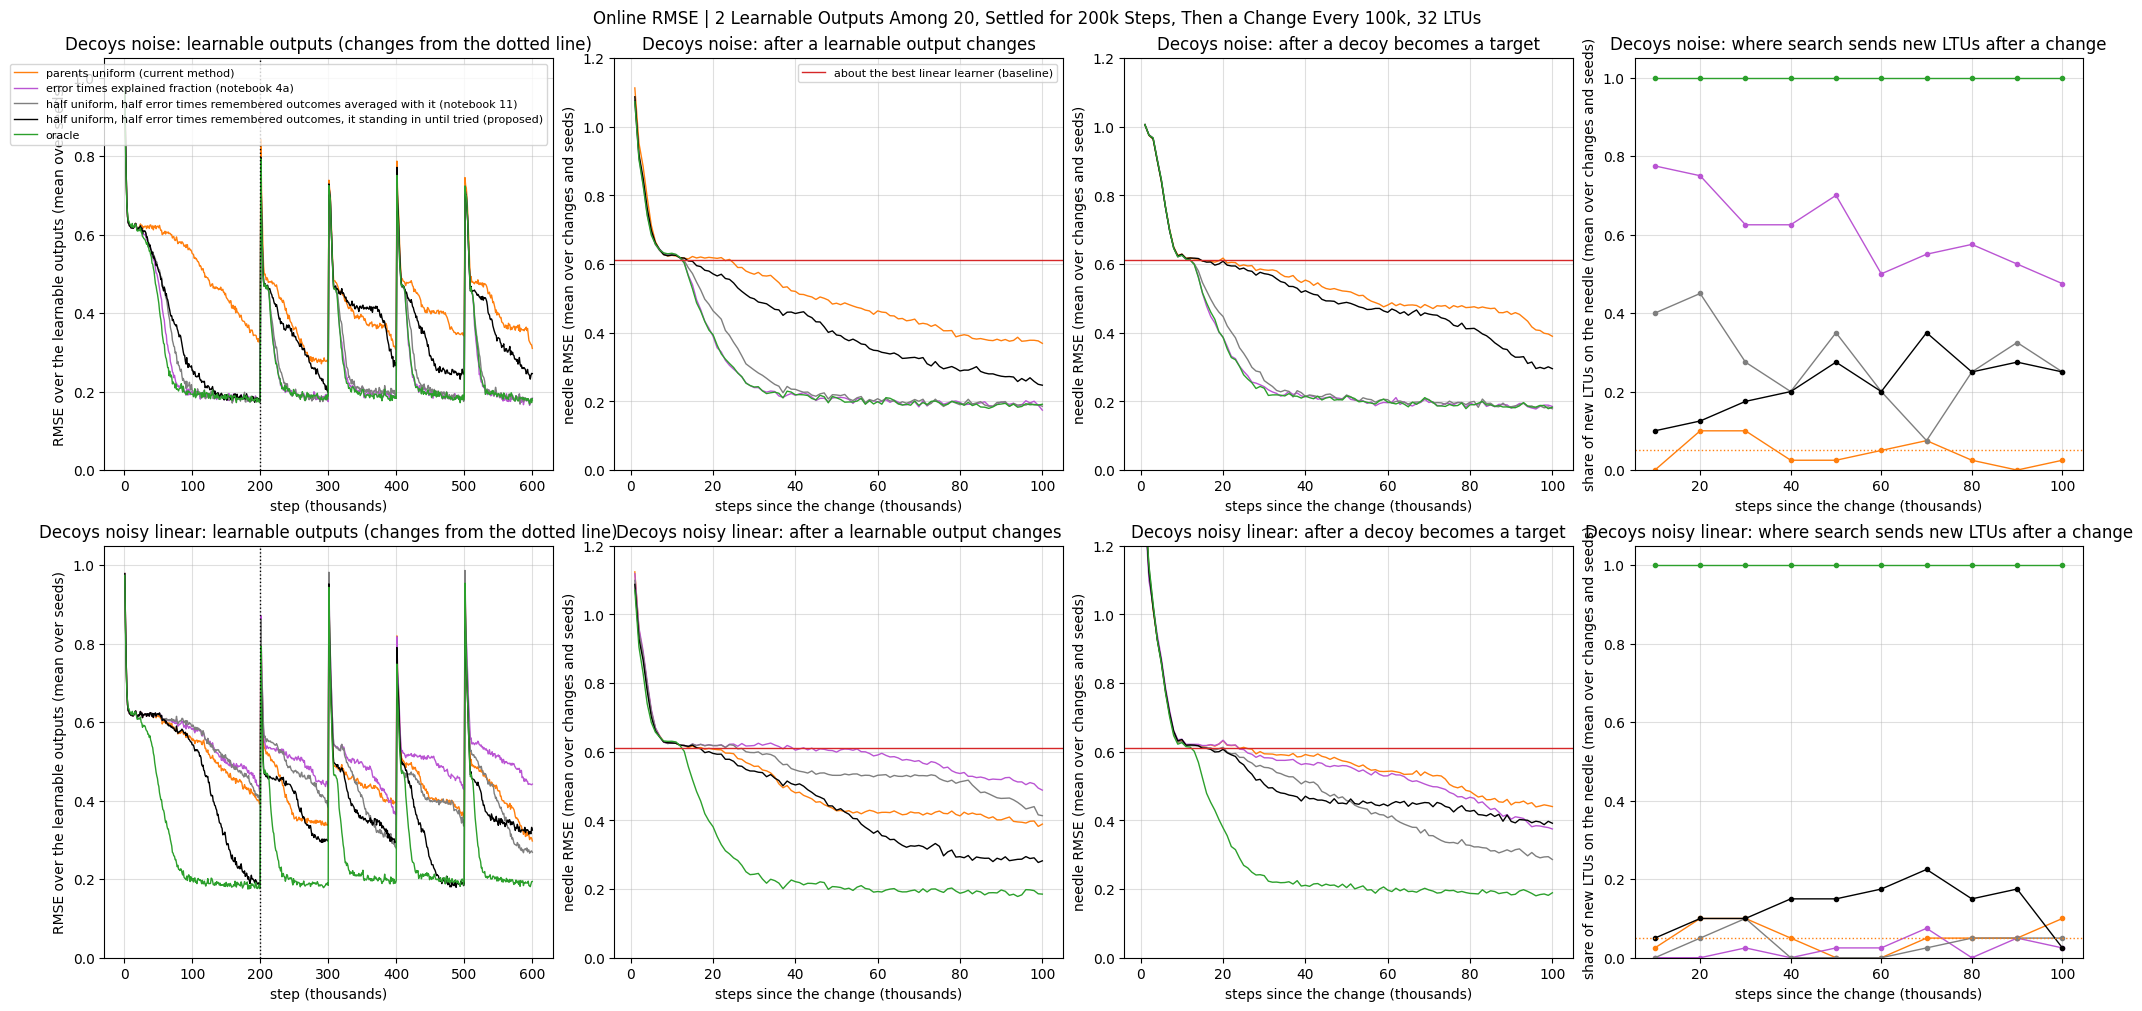

In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
CHANGES = FIRST_CHANGE + CHANGE_EVERY * np.arange(N_CHANGES)
AFTER = CHANGE_EVERY // WINDOW                  # windows from a change to the next
SETTLED = slice((FIRST_CHANGE - CHANGE_EVERY) // WINDOW, FIRST_CHANGE // WINDOW)   # the 100k steps before any change
KINDS = ['a learnable output changes', 'a decoy becomes a target']


def after_changes(curve, kind=None):
    # The windows after each change (of kind 0: a learnable output changes, 1: a decoy becomes a target; None: both),
    # shaped (seed, change, window).
    return np.stack([curve[:, c // WINDOW:c // WINDOW + AFTER] for c in CHANGES[slice(kind, None, 2)]], 1)


fig, axes = plt.subplots(2, 4, figsize=(21, 10), layout='constrained')
for row, (kind, title) in enumerate(PROBLEMS):
    print(title)
    for label, rule, color in RULES:
        rmse, needle, share = results[(kind, rule)]
        axes[row, 0].plot(STEPS / 1000, rmse.mean(0), color=color, lw=1, label=label)
        line = (f'  {label}: RMSE over the 100k steps before any change {rmse[:, SETTLED].mean():.3f} (by seed '
                f'{np.round(rmse[:, SETTLED].mean(1), 3)})')
        for k in range(2):
            after = after_changes(needle, k)
            axes[row, 1 + k].plot(np.arange(1, AFTER + 1), after.mean((0, 1)), color=color, lw=1)
            line += (f'; needle RMSE over the {AFTER}k steps after {KINDS[k]} {after.mean():.3f} '
                     f'(by seed {np.round(after.mean((1, 2)), 3)})')
        shares = after_changes(share)[..., PERIOD // WINDOW - 1::PERIOD // WINDOW]   # (seed, change, search step)
        axes[row, 3].plot(np.arange(1, shares.shape[-1] + 1) * PERIOD / 1000, shares.mean((0, 1)), color=color, lw=1,
                          marker='o', ms=3)
        print(line + f'; share of new LTUs on the needle over the 50k steps after a change '
              f'{shares[..., :5].mean():.2f}')
    axes[row, 0].axvline(FIRST_CHANGE / 1000, color='black', ls=':', lw=1)
    axes[row, 0].set(ylim=(0, 1.05), xlabel='step (thousands)',
                     ylabel='RMSE over the learnable outputs (mean over seeds)',
                     title=f'{title}: learnable outputs (changes from the dotted line)')
    for k in range(2):
        axes[row, 1 + k].set(ylim=(0, 1.2), xlabel='steps since the change (thousands)',
                             ylabel='needle RMSE (mean over changes and seeds)', title=f'{title}: after {KINDS[k]}')
        axes[row, 1 + k].axhline(LINEAR_RMSE, color='tab:red', lw=1, label='about the best linear learner (baseline)')
    axes[row, 3].axhline(1 / N_OUTPUTS, color='tab:orange', ls=':', lw=1)
    axes[row, 3].set(ylim=(0, 1.05), xlabel='steps since the change (thousands)',
                     ylabel='share of new LTUs on the needle (mean over changes and seeds)',
                     title=f'{title}: where search sends new LTUs after a change')
for ax in axes.flat:
    ax.grid(alpha=0.4)
axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8)
fig.suptitle(f'Online RMSE | 2 Learnable Outputs Among 20, Settled for 200k Steps, Then a Change Every 100k, '
             f'{N_LTUS} LTUs')
plt.show()

## Results

**Settled**, remembered outcomes with the explained fraction standing in until tried keep search off the decoys: with
noisy linear decoys, 0.328 over the 100k steps before any change, against 0.477 for uniform parents and 0.511 for
error times explained fraction (better than both in all 5 seeds; oracle 0.188). Averaged with the explained fraction
instead, they do not (0.505). With noise decoys, every rule but uniform parents is near the oracle (0.186 to 0.198).

**After a change** it is slow. With noise decoys, its needle RMSE over the 100k steps after is 0.434 when a learnable
output changes and 0.508 when a decoy becomes a target, against 0.297 and 0.300 for error times explained fraction
(oracle 0.296 and 0.298). With noisy linear decoys, 0.454 and 0.511, against 0.501 and 0.577 for uniform parents
(oracle 0.294 and 0.305). Over the 50k steps after a change, it sends 11% to 17% of new LTUs to the needle, half of
them drawn uniformly; error times explained fraction sends 69% with noise decoys.

**Why** (traced in a separate run of the proposed rule): right after a change, the needle's memory is full of tries
from before it. When a learnable output changes, it holds about 14, mostly the output's own LTUs, which stop helping
as soon as its target changes: its remembered outcome falls from about 0.12 to 0.003 and climbs back only as new LTUs
there succeed, to 0.14 after 90k steps. When a decoy becomes a target, it holds about 2 failed tries from when it was
a decoy. The explained fraction reacts within one search step (0.42 to 0.64 when a learnable output changes), but
once an output has been tried it no longer counts.

## Details

**Remembered outcomes**, as in notebook 11. A trial is an LTU added at a search step; its outcome is its squared
weight to its parent, about the error its removal would add there (its activity is standardized), over the parent's
mean squared error over the search period before it was added. An output's $q_o$ is the mean outcome of the trials
it is or was the parent of, the current ones at their current outcome and the replaced ones at their last, whose
outcomes and count fade by 1/8, the replaced share, per search step. Averaged (notebook 11), the explained fraction
is one more pseudo-trial. Standing in until tried, the pseudo-trial weighs only what the output's (fading) count of
trials lacks below 1: untried, an output gets error times explained fraction; tried once or more, its own outcomes
alone.

**Half uniform.** For both memory rules, at each search step every other replaced LTU (2 of the 4) gets a parent
drawn uniformly; its outcome counts in that parent's memory like any other.

**Decoys.** A learnable output that becomes a decoy becomes the problem's kind of decoy (noise, or noisy linear with
its own linear function); a decoy that becomes a target loses its linear part.

**The rest** is as in notebook 10.